In [ ]:
import rasterio

file_path = "../data/raw/earth/Atacama_Desert.tif"

with rasterio.open(file_path) as src:
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)
    print("Data type:", src.dtypes)

CRS: EPSG:4326
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Width: 3601
Height: 3601
Bounds: BoundingBox(left=-70.00013888888888, bottom=-24.000138888888888, right=-68.9998611111111, top=-22.99986111111111)
NoData: -32767.0
Data type: ('int16',)


In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

dem_path = "../data/raw/earth/Atacama_Desert.tif"

with rasterio.open(dem_path) as src:
    elevation = src.read(1, masked=True)

    valid = elevation.compressed()

    print("Valid pixels:", valid.size)
    print("Total pixels:", elevation.size)
    print("NoData pixels:", elevation.mask.sum())
    print("NoData percentage: {:.2f}%".format(
        100 * elevation.mask.sum() / elevation.size
    ))

    print("\nElevation statistics (meters):")
    print("Minimum:", np.min(valid))
    print("Maximum:", np.max(valid))
    print("Mean:", np.mean(valid))
    print("Median:", np.median(valid))
    print("Standard deviation:", np.std(valid))

    print("\nPercentiles:")
    for p in [5, 25, 50, 75, 95]:
        print("P{}: {:.2f}".format(p, np.percentile(valid, p)))

Matplotlib is building the font cache; this may take a moment.


Valid pixels: 12967201
Total pixels: 12967201
NoData pixels: 0
NoData percentage: 0.00%

Elevation statistics (meters):
Minimum: 618
Maximum: 3389
Mean: 1680.5585383460934
Median: 1604.0
Standard deviation: 575.4667532021699

Percentiles:
P5: 780.00
P25: 1280.00
P50: 1604.00
P75: 2085.00
P95: 2679.00


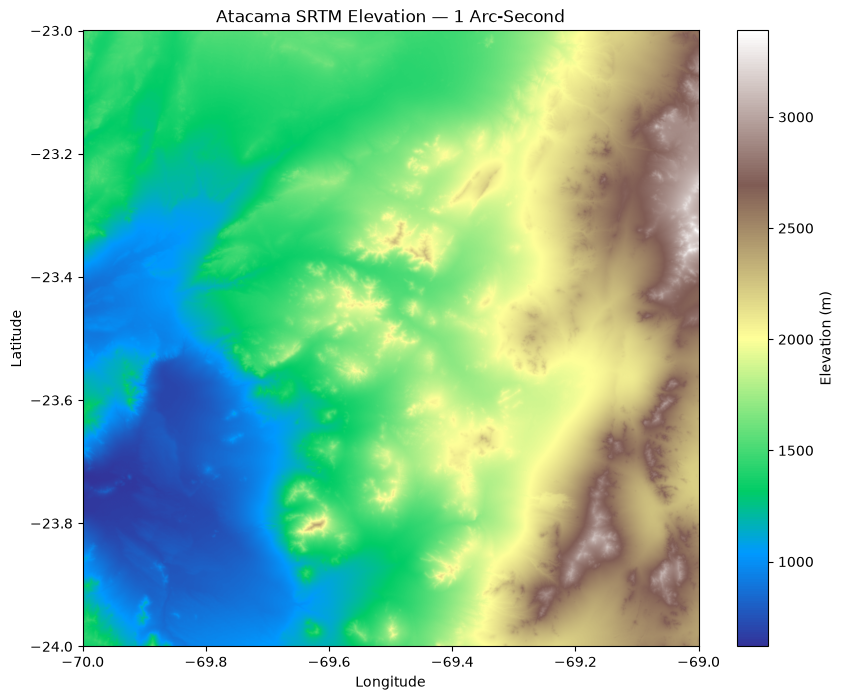

In [5]:
with rasterio.open(dem_path) as src:
    elevation = src.read(1, masked=True)
    bounds = src.bounds

plt.figure(figsize=(10, 8))

plt.imshow(
    elevation,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    cmap="terrain"
)

plt.colorbar(label="Elevation (m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Atacama SRTM Elevation — 1 Arc-Second")

plt.show()